Dataset loading and inspection

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Optional display settings
pd.set_option('display.float_format', '{:.2f}'.format)

# Load data
df = pd.read_csv('../lab-eda-univariate/data/amz_uk_price_prediction_dataset.csv')

# Preview
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.shape
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

No missing values, all good

# Part 1

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [6]:
category_freq = df['category'].value_counts()
category_freq.head(20)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Handmade Gifts                             18295
Handmade Home Décor                        18146
Luggage and travel gear                    18142
Handmade Jewellery                         18044
Handmade Artwork                           17878
Women                                      17772
Handmade Home & Kitchen Products           17435
Handmade Kitchen & Dining                  17432
Men                                        17417
Baby                                       15050
Name: count

In [7]:
category_prop = df['category'].value_counts(normalize=True) * 100
category_summary = pd.DataFrame({
    'count': category_freq,
    'percentage': category_prop
})

category_summary.head(10)

,count,percentage
category,,
Sports & Outdoors,836265,34.22
Beauty,19312,0.79
"Handmade Clothing, Shoes & Accessories",19229,0.79
Bath & Body,19092,0.78
Birthday Gifts,18978,0.78
Manicure & Pedicure Products,18940,0.78
Skin Care,18769,0.77
Make-up,18756,0.77
Hair Care,18735,0.77


In [8]:
top_5_categories = category_summary.head(5)
top_5_categories

,count,percentage
category,,
Sports & Outdoors,836265,34.22
Beauty,19312,0.79
"Handmade Clothing, Shoes & Accessories",19229,0.79
Bath & Body,19092,0.78
Birthday Gifts,18978,0.78


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


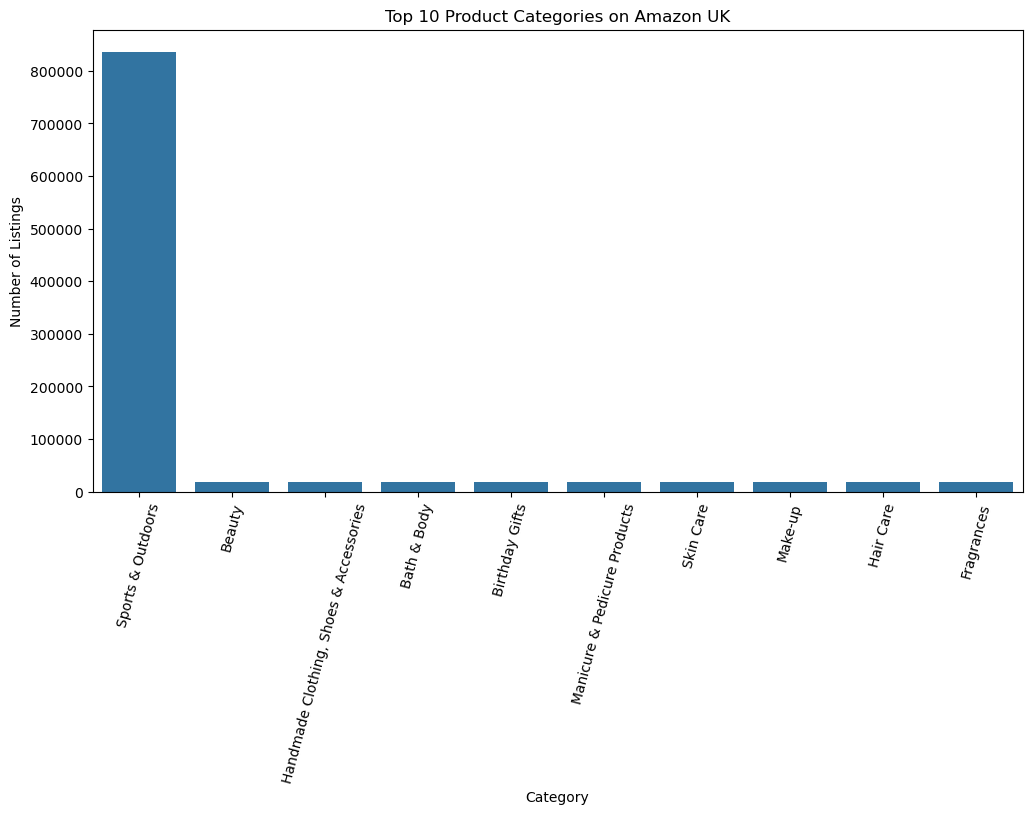

In [12]:
top_10_categories = df['category'].value_counts().head(10)

plt.figure(figsize=(12,6))
sns.barplot(x=top_10_categories.index, y=top_10_categories.values)
plt.title('Top 10 Product Categories on Amazon UK')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=75)
plt.show()

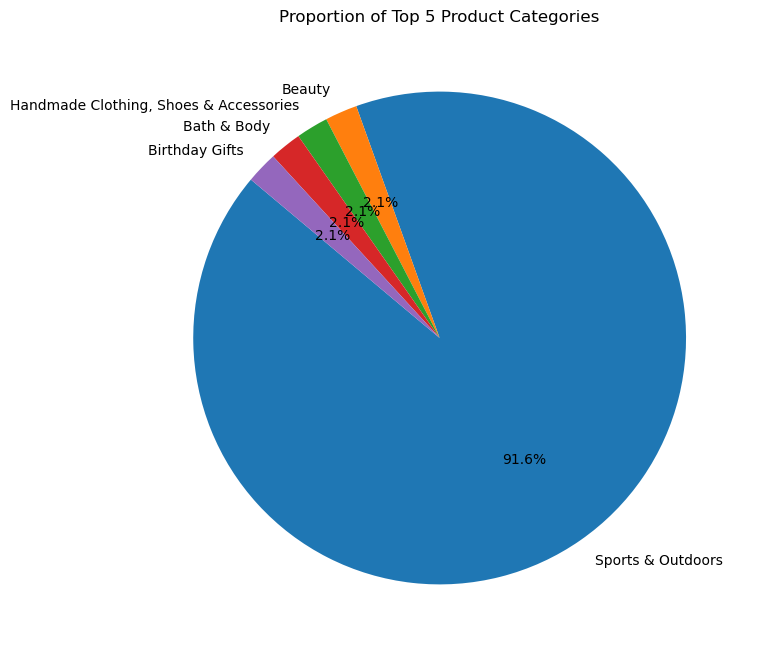

In [10]:
top_5_categories_counts = df['category'].value_counts().head(5)

plt.figure(figsize=(8,8))
plt.pie(top_5_categories_counts.values,
        labels=top_5_categories_counts.index,
        autopct='%1.1f%%',
        startangle=140)
plt.title('Proportion of Top 5 Product Categories')
plt.show()

Sports & Outdoors disproportionally dominates the chart!

# Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [14]:
price_mean = df['price'].mean()
price_median = df['price'].median()
price_mode = df['price'].mode()[0]

print("Mean price:", price_mean)
print("Median price:", price_median)
print("Mode price:", price_mode)

Mean price: 89.24380943923663
Median price: 19.09
Mode price: 9.99


The average price point is 89.24, much higher than the median price (which points to the price distribution being heavily right skewed!).
Most products are surprisingly inexpensive, and the dominant price point is 9.99. However, a handful of very expensive items pulls the mean upwards.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [15]:
price_var = df['price'].var()
price_std = df['price'].std()
price_range = df['price'].max() - df['price'].min()
price_iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print("Variance:", price_var)
print("Standard deviation:", price_std)
print("Range:", price_range)
print("IQR:", price_iqr)

Variance: 119445.48532256528
Standard deviation: 345.60886175352226
Range: 100000.0
IQR: 36.0


Product prices are very spread out. The huge range and the VERY large standard deviation indicate the presence of extreme high-price outliers.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

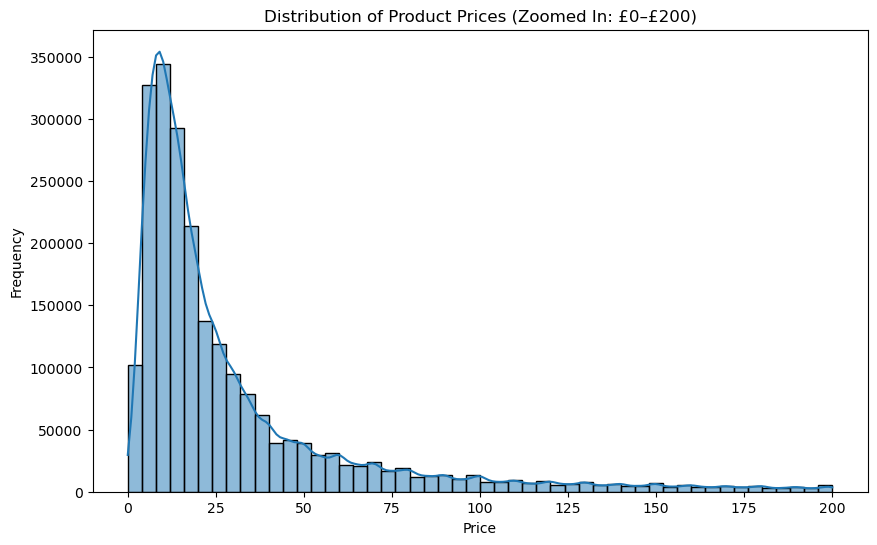

In [19]:
# Had to zoom in the price distribution to get a better view of the majority of products, as there are some very high-priced outliers skewing the distribution.
plt.figure(figsize=(10,6))
sns.histplot(df[df['price'] <= 200]['price'], bins=50, kde=True)
plt.title('Distribution of Product Prices (Zoomed In: £0–£200)')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

Most products appear to cluster in the lower price ranges, somewhere btw 50 and 100 for the most part.

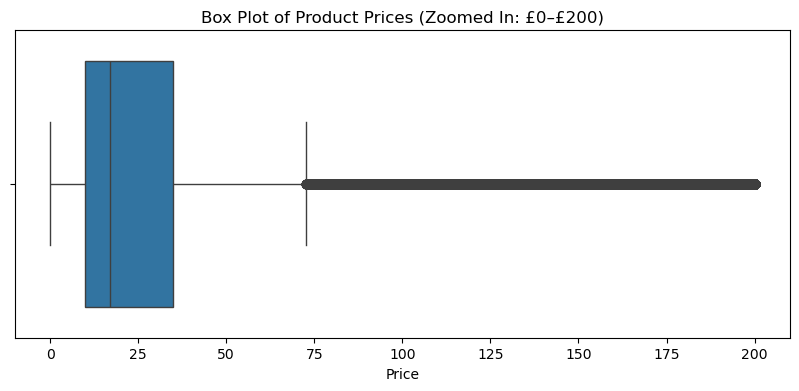

In [18]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df[df['price'] <= 200]['price'])
plt.title('Box Plot of Product Prices (Zoomed In: £0–£200)')
plt.xlabel('Price')
plt.show()

Yes, there are clearly products priced significantly higher than the rest.

# Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [20]:
rating_mean = df['stars'].mean()
rating_median = df['stars'].median()
rating_mode = df['stars'].mode()[0]

print("Mean rating:", rating_mean)
print("Median rating:", rating_median)
print("Mode rating:", rating_mode)

Mean rating: 2.152836472966065
Median rating: 0.0
Mode rating: 0.0


Many products have a rating of 0, which likely means they have not been rated yet, rather than customers actively giving them zero stars. So there is currently a mix of rated and unrated products!

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [23]:
rating_var = df['stars'].var()
rating_std = df['stars'].std()
rating_iqr = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print("Variance:", rating_var)
print("Standard deviation:", rating_std)
print("IQR:", rating_iqr)

Variance: 4.81743402976196
Standard deviation: 2.1948653785054697
IQR: 4.4


3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [24]:
rating_skew = df['stars'].skew()
rating_kurt = df['stars'].kurt()

print("Skewness:", rating_skew)
print("Kurtosis:", rating_kurt)

Skewness: 0.08120735761080985
Kurtosis: -1.9260061280432985


It's hard to answer this follow up question on this exercise, because the ratings don't seem to have been properly accounted for...

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


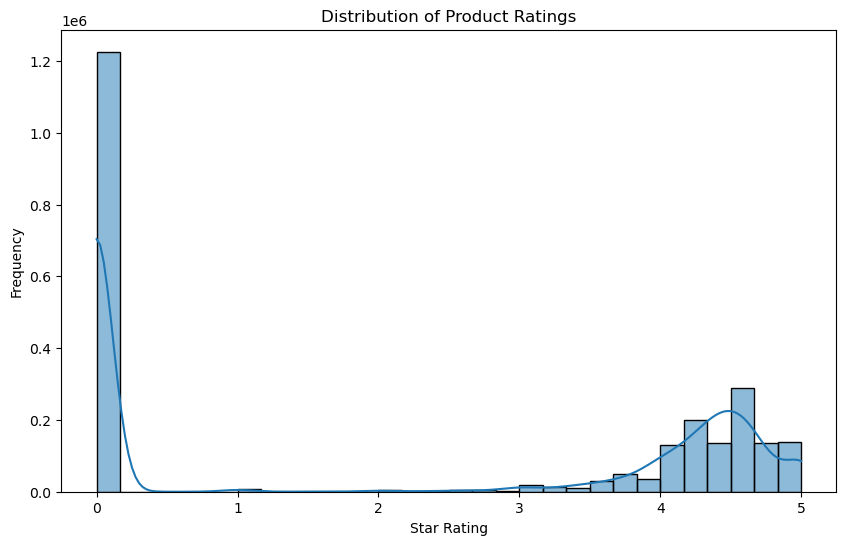

In [25]:
plt.figure(figsize=(10,6))
sns.histplot(df['stars'], bins=30, kde=True)
plt.title('Distribution of Product Ratings')
plt.xlabel('Star Rating')
plt.ylabel('Frequency')
plt.show()

Yes, as it is the most common rating is 0 stars.

# Final Business Summary

Product categories are highly concentrated, with Sports & Outdoors dominating the listings by a large margin. This suggests either strong demand in this segment.

Product pricing is heavily skewed toward lower price ranges. While the average price is relatively high (89.24), the median (19.09) and mode (9.99) show that most products are actually inexpensive. This indicates the presence of a small number of high-priced items that inflate the average, while typical products cluster around lower price points.

Product ratings are more difficult to interpret due to a large number of zero values, which likely represent unrated products rather than negative feedback. However, among rated products, there is a tendency toward higher ratings, suggesting generally positive customer sentiment.

Overall, the analysis shows a marketplace driven by a few dominant categories, competitive low-price positioning, and a large share of products that have yet to build customer feedback — an important factor for visibility and trust.